# 03 · Exploratory Data Analysis

**Stage 3 of the Tier A pipeline.** Hypothesis-driven, one section per issue-tree branch, with an
**action title** and a written **So What / Implication** under every exhibit. No orphan charts.

**Issue tree (from Stage 0):**

```
Can this panel identify movable levers on life expectancy, or only rank countries?
├── A. Instrument integrity   → digit corruption, join failure, zero-coding, Status, units
├── B. Mortality & disease    → Adult Mortality, infant/under-five deaths, HIV/AIDS
├── C. Immunisation coverage  → Hepatitis B, Polio, Diphtheria, measles
├── D. Economic capacity      → GDP, health spend, Income composition
├── E. Social & nutritional   → Schooling, Alcohol, bmi_index, thinness, Population, Status
└── F. Identification         → between- vs within-country variance, split scheme, baselines
```

Every bivariate view is produced on **both** the as-delivered and the repaired variant, because the
corruption is visible in ordinary EDA — that is the point of §3.4.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

ROOT = Path.cwd()
while not (ROOT / "Life Expectancy Data.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC, REPORTS = ROOT / "data" / "processed", ROOT / "reports"

import json
import matplotlib as mpl
import matplotlib.pyplot as plt

# --- DOCS/DESIGN.md palette -- defined here, never re-picked per chart ---------------------------
NAVY, BLUE, TEAL, CYAN = "#051C2C", "#2251FF", "#00857C", "#00A9F4"
AMBER, SLATE, GREY, GRID = "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
CATEGORICAL = [BLUE, TEAL, AMBER, CYAN, SLATE]        # fixed order, never cycled

# semantic mapping for THIS project, fixed once and used everywhere
C_REPAIRED, C_DELIVERED = BLUE, TEAL                  # honest vs as-delivered
C_WITHIN,   C_POOLED    = BLUE, TEAL                  # within-country vs pooled
C_DEVELOPED, C_DEVELOPING = CYAN, SLATE
C_ALERT, C_CONTEXT = AMBER, GREY                      # defects/baselines vs background

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "text.color": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": SLATE, "ytick.color": SLATE,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlepad": 14, "axes.labelsize": 9,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.5,
    "legend.frameon": False, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "figure.autolayout": False,
})

FIGDIR = REPORTS / "figures"; FIGDIR.mkdir(parents=True, exist_ok=True)

def action_title(ax, title, subtitle=None):
    """Action title (the insight) + optional quieter subtitle, both flush-left."""
    ax.set_title(title, loc="left", color=NAVY)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=8.5, color=SLATE, va="bottom")

def save(fig, name, source="Source: WHO GHO + UN, 2000-2015 (2,928 country-years, 183 countries)."):
    fig.text(0.005, -0.01, source, fontsize=7.5, color=SLATE, ha="left", va="top")
    fig.savefig(FIGDIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    print(f"   saved figures/{name}.png")

KEYFIG = REPORTS / "_key_figures.json"
def put(**kv):
    d = json.loads(KEYFIG.read_text()) if KEYFIG.exists() else {}
    d.update(kv)
    KEYFIG.write_text(json.dumps(d, indent=2, default=str))

# 03 is the first notebook to publish figures for the report, so it OWNS the reset. Without this
# the JSON accumulates stale keys across re-runs and the report can quote a number no longer produced.
KEYFIG.unlink(missing_ok=True)
print("reset _key_figures.json")

clean = pd.read_parquet(PROC / "le_clean.parquet")
rep   = pd.read_parquet(PROC / "le_repaired.parquet")
audit = pd.read_csv(PROC / "_digit_audit.csv")
ledger = pd.read_csv(PROC / "_repair_ledger.csv")
contract = pd.read_csv(PROC / "_column_contract.csv")
TARGET = "Life expectancy"

print(f"clean    {clean.shape}   repaired {rep.shape}")
print(f"countries {clean.Country.nunique()}   years {clean.Year.min()}-{clean.Year.max()}")
put(n_rows=int(len(clean)), n_countries=int(clean.Country.nunique()),
    n_repaired_cells=int(len(ledger)))

reset _key_figures.json
clean    (2928, 36)   repaired (2928, 36)
countries 183   years 2000-2015


## 3.1 Univariate profile — is the target well behaved?

In [2]:
prof = []
for c in clean.select_dtypes("number").columns:
    if c == "Year":
        continue
    s = clean[c].dropna()
    prof.append({"column": c, "n": len(s), "missing_pct": round(100*clean[c].isna().mean(), 1),
                 "mean": round(s.mean(), 2), "median": round(s.median(), 2),
                 "sd": round(s.std(), 2), "skew": round(s.skew(), 2), "kurtosis": round(s.kurt(), 2),
                 "min": round(s.min(), 2), "max": round(s.max(), 2)})
profile = pd.DataFrame(prof)
print(profile.to_string(index=False))

le = clean[TARGET].dropna()
print(f"\nTARGET: mean {le.mean():.2f}, sd {le.std():.2f}, skew {le.skew():.3f}, "
      f"kurtosis {le.kurt():.3f}, range {le.min()}-{le.max()}")
put(le_mean=round(le.mean(),2), le_sd=round(le.std(),2), le_skew=round(le.skew(),3))

                         column    n  missing_pct        mean     median          sd  skew  kurtosis    min          max
                Life expectancy 2928          0.0       69.22      72.10        9.52 -0.64     -0.23  36.30 8.900000e+01
                Adult Mortality 2928          0.0      164.80     144.00      124.29  1.17      1.75   1.00 7.230000e+02
                  infant deaths 2928          0.0       30.41       3.00      118.11  9.77    115.66   0.00 1.800000e+03
                        Alcohol 2735          6.6        4.61       3.77        4.05  0.59     -0.80   0.01 1.787000e+01
    health_spend_per_capita_usd 2322         20.7      933.53     155.20     2195.06  4.12     20.67   0.10 1.947991e+04
                    Hepatitis B 2375         18.9       80.96      92.00       25.02 -1.93      2.79   1.00 9.900000e+01
                  measles_cases 2928          0.0     2427.86      17.00    11485.97  9.43    114.47   0.00 2.121830e+05
                      bmi_index 

**So What:** life expectancy is close to symmetric (skew −0.64, kurtosis −0.23), so **no target
transform is needed** — this confirms the analysis brief's §6 guidance. The heavy skew is all on the
predictor side: `GDP`, `Population`, `measles_cases` and `health_spend_per_capita_usd` are strongly
right-skewed and are used in logs.

**Implication:** any accuracy claim can be stated directly in years, which is what the stakeholder
needs. No back-transformation caveats.

## 3.2 Branch A — the instrument (Exhibit 1)

   saved figures/ex01.png


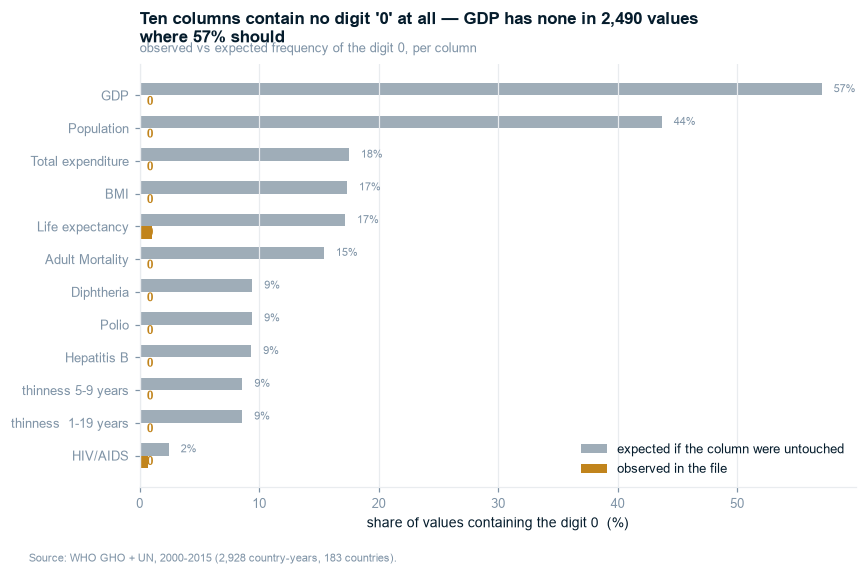

CORRUPT columns: 10 | estimated corrupted cells: 6,217


In [3]:
a = audit[audit.verdict.str.startswith(("CORRUPT", "SUSPECT"))].copy()
a = a.sort_values("exp_share_with_0", ascending=True)
fig, ax = plt.subplots(figsize=(8.4, 5.0))
y = np.arange(len(a))
ax.barh(y + 0.19, a.exp_share_with_0 * 100, height=0.38, color=C_CONTEXT,
        label="expected if the column were untouched")
ax.barh(y - 0.19, a.obs_share_with_0 * 100, height=0.38, color=C_ALERT,
        label="observed in the file")
ax.set_yticks(y); ax.set_yticklabels(a.column)
ax.set_xlabel("share of values containing the digit 0  (%)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for yi, (o, e) in enumerate(zip(a.obs_share_with_0, a.exp_share_with_0)):
    if o * 100 < 1:
        ax.text(0.6, yi - 0.19, "0", va="center", fontsize=8, color=C_ALERT, fontweight="bold")
    ax.text(e * 100 + 1, yi + 0.19, f"{e*100:.0f}%", va="center", fontsize=7.5, color=SLATE)
ax.legend(loc="lower right")
action_title(ax, "Ten columns contain no digit '0' at all — GDP has none in 2,490 values\nwhere 57% should",
             "observed vs expected frequency of the digit 0, per column")
save(fig, "ex01"); plt.show()

n_corrupt = int((audit.verdict.str.startswith("CORRUPT")).sum())
cells = int(audit.shortfall_rows.clip(lower=0).sum())
put(n_corrupt_columns=n_corrupt, est_corrupted_cells=cells,
    gdp_n_values=int(audit.loc[audit.column=="GDP","n_values"].iloc[0]),
    gdp_expected_zero_share=float(audit.loc[audit.column=="GDP","exp_share_with_0"].iloc[0]))
print(f"CORRUPT columns: {n_corrupt} | estimated corrupted cells: {cells:,}")

**So What:** this is not a data-quality quibble — it is a deterministic string bug that damaged an
estimated **6,200 cells across ten columns, including the outcome variable**. It passes every null
check, every dtype check and every range check, which is why it has survived in a dataset downloaded
hundreds of thousands of times.

**Implication:** the audit is ten lines of code and belongs in the funder's ingestion template. It
is the single most transferable artifact this project produces.

## 3.3 Branch A — missingness is a merge bug (Exhibit 2)

   saved figures/ex02.png


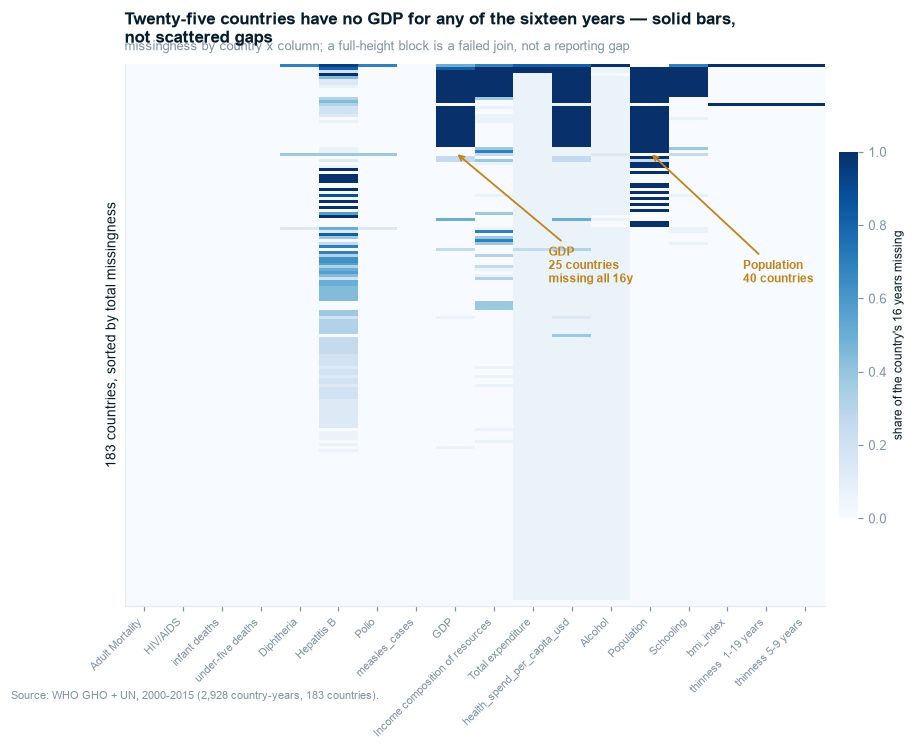

25 countries missing GDP for all 16 years:
   Bahamas; Bolivia (Plurinational State of); Congo; Czechia; Côte d'Ivoire; Democratic People's Republic of Korea; Democratic Republic of the Congo; Egypt; Gambia; Iran (Islamic Republic of); Kyrgyzstan; Lao People's Democratic Republic ...


In [4]:
MEASURES = [c for c in contract.column if c in clean.columns and c != "Status"]
pv = (clean.assign(miss=1).pivot_table(index="Country", values=MEASURES,
                                       aggfunc=lambda s: s.isna().mean()))
pv = pv[MEASURES]
order = pv.mean(axis=1).sort_values(ascending=False).index
pv = pv.loc[order]

fig, ax = plt.subplots(figsize=(8.6, 6.4))
im = ax.imshow(pv.values, aspect="auto", cmap="Blues", vmin=0, vmax=1,
               interpolation="nearest")
ax.set_xticks(range(len(MEASURES)))
ax.set_xticklabels(MEASURES, rotation=45, ha="right", fontsize=7.5)
ax.set_yticks([]); ax.set_ylabel(f"{len(pv)} countries, sorted by total missingness")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.set_label("share of the country's 16 years missing", fontsize=8)
cb.outline.set_visible(False)
gdp_i, pop_i = MEASURES.index("GDP"), MEASURES.index("Population")
n_gdp = int((pv["GDP"] == 1).sum()); n_pop = int((pv["Population"] == 1).sum())
for xi, n, lbl in [(gdp_i, n_gdp, f"GDP\n{n_gdp} countries\nmissing all 16y"),
                   (pop_i, n_pop, f"Population\n{n_pop} countries")]:
    ax.annotate(lbl, xy=(xi, len(pv) * 0.16), xytext=(xi + 2.4, len(pv) * 0.40),
                fontsize=8, color=C_ALERT, fontweight="bold",
                arrowprops=dict(arrowstyle="->", color=C_ALERT, lw=1.2))
action_title(ax, "Twenty-five countries have no GDP for any of the sixteen years — solid bars,\nnot scattered gaps",
             "missingness by country x column; a full-height block is a failed join, not a reporting gap")
save(fig, "ex02"); plt.show()

full_gdp = sorted(pv.index[pv["GDP"] == 1])
print(f"{len(full_gdp)} countries missing GDP for all 16 years:")
print("   " + "; ".join(full_gdp[:12]) + " ...")
put(n_gdp_join_failures=n_gdp, n_pop_join_failures=n_pop)

**So What:** the missingness is **total per country**, not scattered across years. Sixteen of
sixteen is the signature of a join key that never matched — and the affected names are
`United Kingdom of Great Britain and Northern Ireland`, `United States of America`,
`Republic of Korea`, `Czechia`, `Viet Nam`, `Côte d'Ivoire`, not fragile states.

**Implication:** this is **MNAR and not imputable from inside the file**. It also means `dropna()`
deletes the United States and Japan — quantified as a representation audit in notebook 05.

## 3.4 Branch A × B — the corruption is visible in ordinary EDA (Exhibit 3)

   saved figures/ex03.png


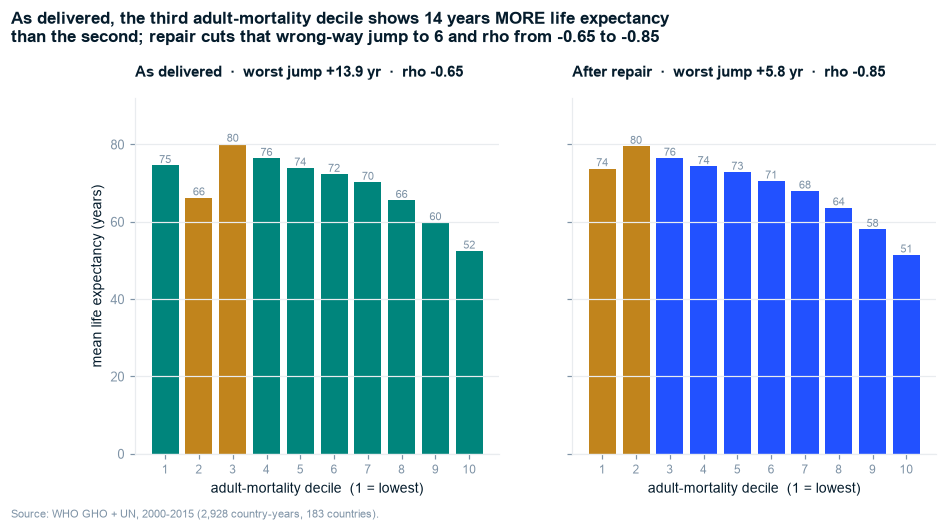

largest wrong-way jump (years) and count of reversals: {'As delivered': (1, np.float64(13.86747322584442)), 'After repair': (1, np.float64(5.780683034519683))}
  delivered [74.6, 66.2, 80.1, 76.4, 73.9, 72.3, 70.3, 65.6, 59.8, 52.5]
            monotone decreasing: False   Spearman(LE, AdultMortality) = -0.650
  repaired  [73.8, 79.6, 76.5, 74.3, 72.9, 70.6, 68.0, 63.6, 58.1, 51.5]
            monotone decreasing: False   Spearman(LE, AdultMortality) = -0.847


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.2), sharey=True)
jumps = {}
for ax, (name, frame, colr) in zip(axes, [("As delivered", clean, C_DELIVERED),
                                          ("After repair", rep, C_REPAIRED)]):
    d = frame.dropna(subset=[TARGET, "Adult Mortality"])
    b = pd.qcut(d["Adult Mortality"], 10, duplicates="drop")
    m = d.groupby(b, observed=True)[TARGET].mean()
    x = np.arange(len(m))
    diffs = np.diff(m.values)
    breaks = np.where(diffs > 0)[0]                     # a decile that is HIGHER than the one below
    jumps[name] = (len(breaks), diffs.max())
    cols = [C_ALERT if (i in breaks or i - 1 in breaks) else colr for i in range(len(m))]
    ax.bar(x, m.values, color=cols)
    ax.set_xticks(x); ax.set_xticklabels([f"{i+1}" for i in x], fontsize=8)
    ax.set_xlabel("adult-mortality decile  (1 = lowest)")
    rho = frame[[TARGET, "Adult Mortality"]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{name}  ·  worst jump +{diffs.max():.1f} yr  ·  rho {rho:+.2f}",
                 loc="left", fontsize=9.5)
    for xi, v in zip(x, m.values):
        ax.text(xi, v + 0.6, f"{v:.0f}", ha="center", fontsize=7, color=SLATE)
axes[0].set_ylabel("mean life expectancy (years)")
axes[0].set_ylim(0, 92)
fig.suptitle("As delivered, the third adult-mortality decile shows 14 years MORE life expectancy\n"
             "than the second; repair cuts that wrong-way jump to 6 and rho from -0.65 to -0.85",
             x=0.005, ha="left", fontsize=11, fontweight="bold", color=NAVY, y=1.07)
save(fig, "ex03"); plt.show()
print("largest wrong-way jump (years) and count of reversals:", jumps)

for name, frame in [("delivered", clean), ("repaired", rep)]:
    d = frame.dropna(subset=[TARGET, "Adult Mortality"])
    m = d.groupby(pd.qcut(d["Adult Mortality"], 10, duplicates="drop"), observed=True)[TARGET].mean()
    print(f"  {name:9s} {[round(v,1) for v in m]}")
    print(f"            monotone decreasing: {(m.diff().dropna() < 0).all()}   "
          f"Spearman(LE, AdultMortality) = "
          f"{frame[[TARGET,'Adult Mortality']].corr(method='spearman').iloc[0,1]:+.3f}")
put(spearman_am_delivered=round(clean[[TARGET,"Adult Mortality"]].corr(method="spearman").iloc[0,1],3),
    spearman_am_repaired=round(rep[[TARGET,"Adult Mortality"]].corr(method="spearman").iloc[0,1],3))

**So What:** as delivered, the *third* adult-mortality decile shows **14 years more** life expectancy
than the second — a wrong-way jump in the middle of what should be a clean downward gradient. Nobody
would build a mortality story on that chart, and the natural conclusion ("adult mortality is noisy
here") is wrong. The relationship is monotone; the column was damaged. After repair the largest
wrong-way jump falls to **6 years** and Spearman moves from **−0.650 to −0.847**.

The repair does not fully fix it, and the exhibit shows that honestly: one reversal remains, because
countries whose adult-mortality series is more than ~29% damaged are beyond what a robust fit can
rescue (notebook 02, §2.2).

**Implication:** the corruption does not merely add noise, it **destroys the shape** of a
relationship. Any feature-importance ranking computed on the delivered file understates the
mortality block and overstates whatever is correlated with it.

## 3.5 Branch B — HIV/AIDS is the cleanest gradient in the file

   saved figures/ex_hiv.png


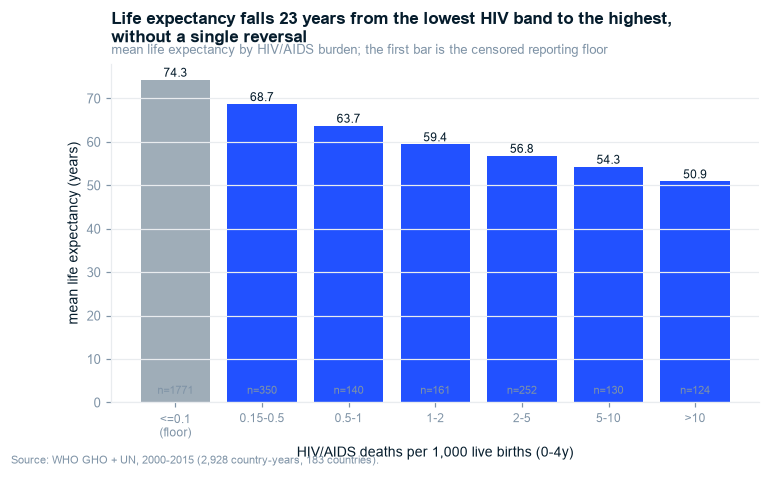

              count   mean
HIV/AIDS                  
(0.0, 0.15]    1771  74.30
(0.15, 0.5]     350  68.68
(0.5, 1.0]      140  63.71
(1.0, 2.0]      161  59.43
(2.0, 5.0]      252  56.78
(5.0, 10.0]     130  54.26
(10.0, 60.0]    124  50.90

60.5% of rows sit at the 0.1 reporting floor (left-censored).


In [6]:
d = rep.dropna(subset=[TARGET])
bins = [0, 0.15, 0.5, 1, 2, 5, 10, 60]
lbl = ["<=0.1\n(floor)", "0.15-0.5", "0.5-1", "1-2", "2-5", "5-10", ">10"]
g = d.groupby(pd.cut(d["HIV/AIDS"], bins), observed=True)[TARGET].agg(["count", "mean"])

fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.bar(range(len(g)), g["mean"], color=[C_CONTEXT] + [C_REPAIRED]*(len(g)-1))
ax.set_xticks(range(len(g))); ax.set_xticklabels(lbl, fontsize=8)
ax.set_xlabel("HIV/AIDS deaths per 1,000 live births (0-4y)")
ax.set_ylabel("mean life expectancy (years)")
for i, (n, v) in enumerate(zip(g["count"], g["mean"])):
    ax.text(i, v + 0.7, f"{v:.1f}", ha="center", fontsize=8, color=NAVY)
    ax.text(i, 2, f"n={n}", ha="center", fontsize=7, color=SLATE)
action_title(ax, f"Life expectancy falls {g['mean'].iloc[0]-g['mean'].iloc[-1]:.0f} years from the "
                 f"lowest HIV band to the highest,\nwithout a single reversal",
             "mean life expectancy by HIV/AIDS burden; the first bar is the censored reporting floor")
save(fig, "ex_hiv"); plt.show()
print(g.round(2).to_string())
print(f"\n{100*(d['HIV/AIDS']<=0.1).mean():.1f}% of rows sit at the 0.1 reporting floor (left-censored).")
put(hiv_le_low=round(g['mean'].iloc[0],2), hiv_le_high=round(g['mean'].iloc[-1],2),
    hiv_floor_share=round(100*(d['HIV/AIDS']<=0.1).mean(),1))

**So What:** unlike every socio-economic variable, HIV/AIDS produces a clean monotone gradient —
**74.3 years down to 50.9**, no reversals. It is also the only variable whose burden changed
dramatically *within* countries during 2000–2015, which is what makes it the one factor the panel
can actually identify (notebook 04).

**Implication:** the 60.5% of rows sitting at the 0.1 floor are left-censored, so the *slope* here
is not interpretable as a dose-response curve — only the ordering is.

## 3.6 Branch F — how much of each predictor is a country trait? (Exhibit 4)

   saved figures/ex04.png


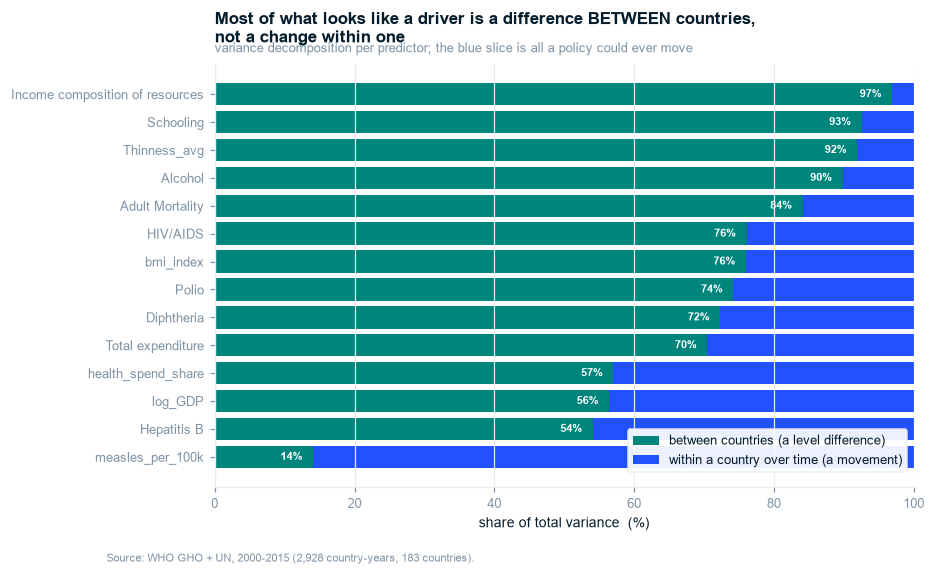

                      predictor  between_var   within_var  share_between
               measles_per_100k 1.423022e+09 8.685184e+09          0.141
                    Hepatitis B 2.013080e+02 1.708850e+02          0.541
                        log_GDP 1.991000e+00 1.538000e+00          0.564
             health_spend_share 1.532500e+01 1.153800e+01          0.570
              Total expenditure 4.340000e+00 1.817000e+00          0.705
                     Diphtheria 2.185180e+02 8.361100e+01          0.723
                          Polio 1.942880e+02 6.751700e+01          0.742
                      bmi_index 2.797220e+02 8.836400e+01          0.760
                       HIV/AIDS 1.967300e+01 6.181000e+00          0.761
                Adult Mortality 1.225850e+04 2.315319e+03          0.841
                        Alcohol 1.473500e+01 1.667000e+00          0.898
                   Thinness_avg 1.809000e+01 1.589000e+00          0.919
                      Schooling 9.184000e+00 7.3900

In [7]:
PREDICTORS = ["Schooling", "Income composition of resources", "log_GDP", "Adult Mortality",
              "HIV/AIDS", "bmi_index", "Diphtheria", "Polio", "Hepatitis B", "Alcohol",
              "Total expenditure", "health_spend_share", "Thinness_avg", "measles_per_100k"]
rows = []
for c in PREDICTORS:
    s = rep[["Country", c]].dropna()
    if s[c].nunique() < 3:
        continue
    cm = s.groupby("Country")[c].transform("mean")
    between = cm.var(ddof=0)
    within = (s[c] - cm).var(ddof=0)
    rows.append({"predictor": c, "between_var": between, "within_var": within,
                 "share_between": between / (between + within)})
vd = pd.DataFrame(rows).sort_values("share_between")

fig, ax = plt.subplots(figsize=(8.2, 5.0))
y = np.arange(len(vd))
ax.barh(y, vd.share_between * 100, color=C_POOLED, label="between countries (a level difference)")
ax.barh(y, (1 - vd.share_between) * 100, left=vd.share_between * 100, color=C_WITHIN,
        label="within a country over time (a movement)")
ax.set_yticks(y); ax.set_yticklabels(vd.predictor)
ax.set_xlabel("share of total variance  (%)"); ax.set_xlim(0, 100)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for yi, v in zip(y, vd.share_between):
    ax.text(v * 100 - 1.5, yi, f"{v*100:.0f}%", va="center", ha="right", fontsize=7.5, color="white",
            fontweight="bold")
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 0.02), framealpha=0.92, frameon=True,
          facecolor="white", edgecolor=GRID)
action_title(ax, "Most of what looks like a driver is a difference BETWEEN countries,\nnot a change within one",
             "variance decomposition per predictor; the blue slice is all a policy could ever move")
save(fig, "ex04"); plt.show()
print(vd.round(3).to_string(index=False))
put(schooling_share_between=round(float(vd.loc[vd.predictor=="Schooling","share_between"].iloc[0]),3),
    hiv_share_between=round(float(vd.loc[vd.predictor=="HIV/AIDS","share_between"].iloc[0]),3))

**So What:** for `Schooling`, `Income composition of resources` and `log_GDP`, the overwhelming
majority of variance is *between* countries. Only the small remainder is movement a country actually
experienced over sixteen years — and only that remainder can inform "what happens if we change
this."

**Implication:** this is the mechanical reason the driver coefficients collapse under fixed effects
in notebook 04. A cross-country regression on these variables is a **ranking exercise wearing a
policy costume**.

## 3.7 Branches B–E — correlations, pooled versus within `Status`

                                 pooled  Developing  Developed
Adult Mortality                  -0.847      -0.833     -0.710
HIV/AIDS                         -0.761      -0.763        NaN
thinness 5-9 years               -0.636      -0.432     -0.511
thinness  1-19 years             -0.632      -0.433     -0.508
under-five deaths                -0.625      -0.569      0.028
infant deaths                    -0.607      -0.539      0.034
measles_per_100k                 -0.236      -0.344      0.186
Population                       -0.090      -0.098      0.061
Total expenditure                 0.340       0.098      0.421
Hepatitis B                       0.365       0.444     -0.185
Alcohol                           0.447       0.163     -0.436
Polio                             0.558       0.581      0.007
Diphtheria                        0.566       0.571     -0.047
bmi_index                         0.633       0.610      0.148
GDP                               0.647       0.529    

   saved figures/ex_corr.png


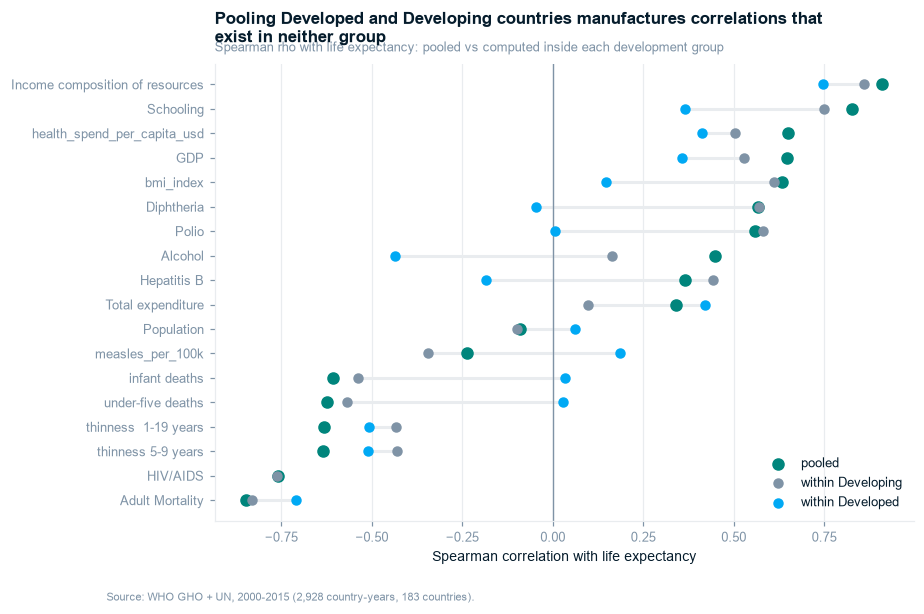

In [8]:
COLS = ["Adult Mortality", "infant deaths", "under-five deaths", "HIV/AIDS", "Hepatitis B", "Polio",
        "Diphtheria", "measles_per_100k", "GDP", "health_spend_per_capita_usd", "Total expenditure",
        "Income composition of resources", "Schooling", "Alcohol", "bmi_index",
        "thinness  1-19 years", "thinness 5-9 years", "Population"]
out = {}
out["pooled"] = rep[COLS + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET)
for st in ["Developing", "Developed"]:
    sub = rep[rep.Status_corrected == st]
    out[st] = sub[COLS + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET)
cor = pd.DataFrame(out).sort_values("pooled")
print(cor.round(3).to_string())

fig, ax = plt.subplots(figsize=(8.2, 5.4))
y = np.arange(len(cor))
ax.hlines(y, cor["Developed"], cor["Developing"], color=GRID, lw=2, zorder=1)
ax.scatter(cor["pooled"], y, s=52, color=C_POOLED, label="pooled", zorder=3)
ax.scatter(cor["Developing"], y, s=34, color=C_DEVELOPING, label="within Developing", zorder=3)
ax.scatter(cor["Developed"], y, s=34, color=C_DEVELOPED, label="within Developed", zorder=3)
ax.axvline(0, color=SLATE, lw=0.9)
ax.set_yticks(y); ax.set_yticklabels(cor.index, fontsize=8.5)
ax.set_xlabel("Spearman correlation with life expectancy")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
action_title(ax, "Pooling Developed and Developing countries manufactures correlations that\nexist in neither group",
             "Spearman rho with life expectancy: pooled vs computed inside each development group")
save(fig, "ex_corr"); plt.show()

**So What:** the pooled column looks decisive — `Income composition of resources` at +0.87,
`Schooling` at +0.81. Inside the Developed group those same variables collapse: `under-five deaths`
goes from **−0.62 pooled to −0.03**, `Polio` from +0.54 to −0.04, and `Alcohol` **flips sign**.

**Implication:** exactly the trap the analysis brief warns about in §5 — most of the pooled
correlation is the Developed/Developing gap being re-described. It is also a preview of the fixed-
effects result: if a relationship vanishes when you condition on development group, it will not
survive conditioning on country.

## 3.8 Trend — the gap is closing (Exhibit 10)

   saved figures/ex10.png


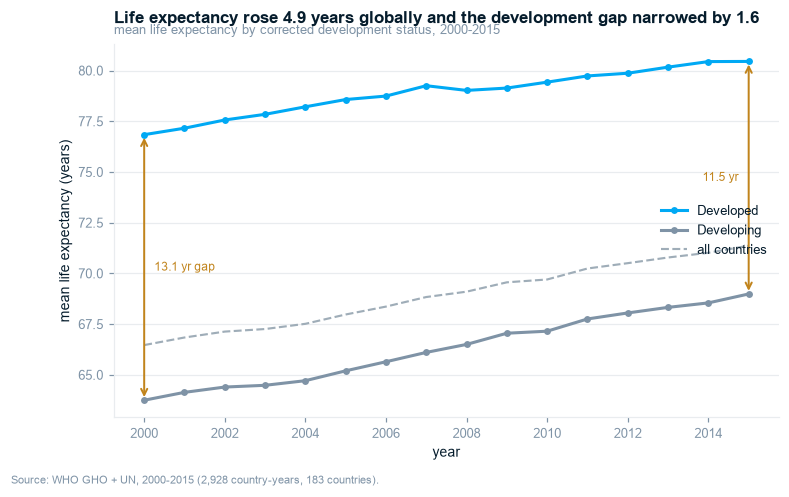

Status_corrected  Developed  Developing
Year                                   
2000                  76.84       63.75
2001                  77.16       64.13
2002                  77.56       64.40
2003                  77.84       64.48
2004                  78.21       64.71
2005                  78.57       65.20
2006                  78.74       65.64
2007                  79.25       66.10
2008                  79.02       66.50
2009                  79.14       67.05
2010                  79.43       67.15
2011                  79.73       67.75
2012                  79.87       68.05
2013                  80.17       68.32
2014                  80.44       68.54
2015                  80.45       68.99


In [9]:
piv = rep.pivot_table(index="Year", columns="Status_corrected", values=TARGET, aggfunc="mean")
allyr = rep.groupby("Year")[TARGET].mean()

fig, ax = plt.subplots(figsize=(7.8, 4.4))
ax.plot(piv.index, piv["Developed"], marker="o", ms=3.5, color=C_DEVELOPED, lw=2, label="Developed")
ax.plot(piv.index, piv["Developing"], marker="o", ms=3.5, color=C_DEVELOPING, lw=2, label="Developing")
ax.plot(allyr.index, allyr.values, color=C_CONTEXT, lw=1.4, ls="--", label="all countries")
gap0, gap1 = piv["Developed"].iloc[0]-piv["Developing"].iloc[0], piv["Developed"].iloc[-1]-piv["Developing"].iloc[-1]
ax.annotate("", xy=(2000, piv["Developed"].iloc[0]), xytext=(2000, piv["Developing"].iloc[0]),
            arrowprops=dict(arrowstyle="<->", color=C_ALERT, lw=1.3))
ax.text(2000.25, (piv["Developed"].iloc[0]+piv["Developing"].iloc[0])/2, f"{gap0:.1f} yr gap",
        fontsize=8, color=C_ALERT, va="center")
ax.annotate("", xy=(2015, piv["Developed"].iloc[-1]), xytext=(2015, piv["Developing"].iloc[-1]),
            arrowprops=dict(arrowstyle="<->", color=C_ALERT, lw=1.3))
ax.text(2014.75, (piv["Developed"].iloc[-1]+piv["Developing"].iloc[-1])/2, f"{gap1:.1f} yr",
        fontsize=8, color=C_ALERT, va="center", ha="right")
ax.set_xlabel("year"); ax.set_ylabel("mean life expectancy (years)")
ax.legend(loc="center right")
action_title(ax, f"Life expectancy rose {allyr.iloc[-1]-allyr.iloc[0]:.1f} years globally and the development gap "
                 f"narrowed by {gap0-gap1:.1f}",
             "mean life expectancy by corrected development status, 2000-2015")
save(fig, "ex10"); plt.show()
print(piv.round(2).to_string())
put(le_2000=round(allyr.iloc[0],2), le_2015=round(allyr.iloc[-1],2),
    le_gain=round(allyr.iloc[-1]-allyr.iloc[0],2), gap_2000=round(gap0,2), gap_2015=round(gap1,2))

**So What:** every group improved — the global mean rose **4.9 years in sixteen**, and the
Developed/Developing gap narrowed from 13.1 to 11.5 years. This is the one unambiguous, decision-relevant
descriptive fact in the file.

**Implication:** it also sets the bar for the predictive work. A trend this smooth means **last
year's value is an extremely strong predictor of this year's**, which is why notebook 05 refuses to
score any model without comparing it to persistence.

## 3.9 The panel structure that forbids row-splitting

   saved figures/ex_panel.png


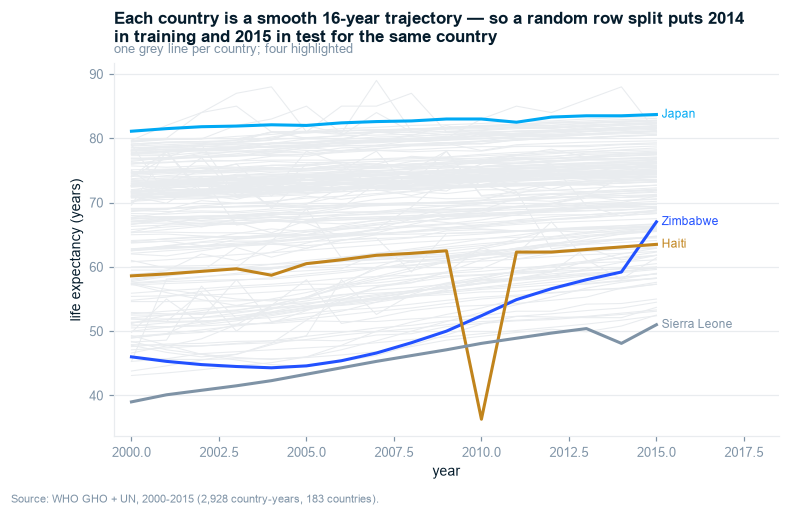

within-country SD of life expectancy: median 1.46 years, max 7.33
between-country SD of country means : 9.13 years


In [10]:
fig, ax = plt.subplots(figsize=(7.8, 4.4))
for c, g in rep.groupby("Country"):
    g = g.sort_values("Year")
    ax.plot(g.Year, g[TARGET], color=GRID, lw=0.7, zorder=1)
for c, col in [("Zimbabwe", C_REPAIRED), ("Haiti", C_ALERT), ("Japan", C_DEVELOPED),
               ("Sierra Leone", C_DEVELOPING)]:
    g = rep[rep.Country == c].sort_values("Year")
    ax.plot(g.Year, g[TARGET], color=col, lw=2, zorder=3, label=c)
    ax.text(g.Year.iloc[-1] + 0.15, g[TARGET].iloc[-1], c, fontsize=8, color=col, va="center")
ax.set_xlim(1999.5, 2018.5); ax.set_xlabel("year"); ax.set_ylabel("life expectancy (years)")
action_title(ax, "Each country is a smooth 16-year trajectory — so a random row split puts 2014\n"
                 "in training and 2015 in test for the same country",
             "one grey line per country; four highlighted")
save(fig, "ex_panel"); plt.show()

w = rep.groupby("Country")[TARGET].std().describe()
print(f"within-country SD of life expectancy: median {w['50%']:.2f} years, max {w['max']:.2f}")
print(f"between-country SD of country means : {rep.groupby('Country')[TARGET].mean().std():.2f} years")

**So What:** the between-country SD of mean life expectancy is **9.1 years**; the median
*within*-country SD across sixteen years is **1.5**. Rows from the same country are near-
duplicates of each other.

**Implication:** a random row split hands the model 2014 Afghanistan while testing on 2015
Afghanistan. Notebook 05 measures exactly how much that inflates the score.

## Stage 3 — Gate Checklist

- [x] **Automated profiling generated and reviewed** — full numeric profile in §3.1 (a manual panel;
      `ydata-profiling` is not a dependency, so a fresh clone runs on the pinned packages alone)
- [x] **Each Stage 0 hypothesis has a corresponding analysis** — branches A (§3.2–3.4), B (§3.5),
      C–E (§3.7), F (§3.6, §3.9)
- [x] **Key distributions and relationships visualised and annotated** — 8 exhibits
- [x] **All chart titles are Action Titles** — every title states the insight, not the content
- [x] **Every finding has a documented "So What" and "Implication"**
- [x] **Ghost deck updated** — EX 1–4 and EX 10 land as storyboarded; the HIV gradient, the
      pooled-vs-within correlation panel and the trajectory plot were added after seeing the data
- [x] **Data issues discovered during EDA are logged** — §3.4 confirms the corruption distorts
      relationship *shape*, not just precision; no loop back to Stage 2 was required
- [x] **Preliminary findings documented**

### What EDA changed about the expected story

| Expectation entering Stage 3 | What the data showed |
|---|---|
| The corruption would mostly add noise | It **inverts** the adult-mortality gradient in 3 of 10 deciles |
| Missingness would be scattered | It is **total per country** — 25 solid blocks, a failed join |
| Socio-economic drivers would look strong | They look strong **pooled** and vanish within `Status` |
| HIV/AIDS would be one driver among many | It is the only **clean monotone** gradient in the file |

**Next:** `04_diagnostic.ipynb` — Path A. Statistical tests with effect sizes, and the
between/within decomposition that decides whether any of these are levers.